# Boxscore AI — NBA Game Outcome Prediction

Predict team wins using only statistics available **before** each game. Dataset: 2024–25 NBA regular season. Each game is represented by two team rows.

## 1. Imports

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

## 2. Load game data

The local SQLite database is populated by `main.py` (which retrieves games from `nba_api`).

In [2]:
with sqlite3.connect("boxscore_ai.db") as conn:
    df = pd.read_sql_query("SELECT * FROM games", conn)

print(f"Loaded {len(df):,} team-game rows and {df['GAME_ID'].nunique():,} games")
df.head()

Loaded 2,460 team-game rows and 1,230 games


,GAME_ID,TEAM_ID,SEASON_ID,GAME_DATE,TEAM_ABBREVIATION,MATCHUP,WL,PTS,AST,STL,BLK,TOV,FGM,FGA,FG_PCT,FG3M,FG3A,FTM,FTA,OREB,DREB,REB
0,22400062,1610612750,22024,2024-10-22,MIN,MIN @ LAL,L,103,17,4,1,16,35,85,0.412,13,41,20,27,12,35,47
1,22400062,1610612747,22024,2024-10-22,LAL,LAL vs. MIN,W,110,22,7,8,7,42,95,0.442,5,30,21,25,15,31,46
2,22400061,1610612738,22024,2024-10-22,BOS,BOS vs. NYK,W,132,33,6,3,4,48,95,0.505,29,61,7,8,11,29,40
3,22400061,1610612752,22024,2024-10-22,NYK,NYK @ BOS,L,109,20,2,3,12,43,78,0.551,11,30,12,16,5,29,34
4,22400065,1610612753,22024,2024-10-23,ORL,ORL @ MIA,W,116,28,8,8,14,41,96,0.427,18,49,16,22,18,39,57


## 3. Leakage-safe historical features

For each team, calculate the mean of its **previous five games**. `shift(1)` prevents current-game box-score statistics from entering the predictors. The first five team-games have insufficient history.

In [3]:
df_copy = df.sort_values(["GAME_DATE", "GAME_ID", "TEAM_ID"]).copy()
stats = ["PTS", "FG_PCT", "AST", "REB"]
for col in stats:
    df_copy[f"{col}_last_5_games_avg"] = (
        df_copy.groupby("TEAM_ID")[col]
        .transform(lambda s: s.shift(1).rolling(5).mean())
    )
df_copy = df_copy.dropna(subset=[f"{col}_last_5_games_avg" for col in stats]).copy()
print(f"Rows with five-game history: {len(df_copy):,}")

Rows with five-game history: 2,310


## 4. Match each team with its opponent

Only retain games with both team records. Self-join on `GAME_ID`, exclude same-team matches, and add the opponent’s *historical* features. `IS_HOME` comes from the matchup string.

In [4]:
game_counts = df_copy.groupby("GAME_ID").size()
complete_ids = game_counts[game_counts == 2].index
complete_games = df_copy[df_copy["GAME_ID"].isin(complete_ids)].copy()
merged_games = complete_games.merge(complete_games, on="GAME_ID", suffixes=("_x", "_y"))
model_games = merged_games.loc[merged_games["TEAM_ID_x"] != merged_games["TEAM_ID_y"]].copy()
model_games = model_games.rename(columns={
    f"{col}_last_5_games_avg_y": f"OPP_{col}_last_5_games_avg" for col in stats
})
model_games["IS_HOME"] = model_games["MATCHUP_x"].str.contains("vs.", regex=False).astype(int)
model_games = model_games.sort_values(["GAME_DATE_x", "GAME_ID", "TEAM_ID_x"]).copy()
assert model_games.groupby("GAME_ID").size().eq(2).all()
print(f"Complete games: {model_games['GAME_ID'].nunique():,}; team rows: {len(model_games):,}")

Complete games: 1,152; team rows: 2,304


## 5. Chronological train/test split

Split by **unique game dates**, not randomly. Both team records of each game must stay in the same split. Features contain historical averages and home/away only—never the current game’s points, shooting, or result.

In [5]:
unique_dates = model_games["GAME_DATE_x"].unique()
cutoff_date = unique_dates[int(len(unique_dates) * 0.8)]
train_df_improved = model_games[model_games["GAME_DATE_x"] < cutoff_date].copy()
test_df_improved = model_games[model_games["GAME_DATE_x"] >= cutoff_date].copy()
features = (
    [f"{col}_last_5_games_avg_x" for col in stats]
    + [f"OPP_{col}_last_5_games_avg" for col in stats]
    + ["IS_HOME"]
)
X_train, X_test = train_df_improved[features], test_df_improved[features]
y_train, y_test = train_df_improved["WL_x"], test_df_improved["WL_x"]
y_train_binary = (y_train == "W").astype(int)
y_test_binary = (y_test == "W").astype(int)
assert set(train_df_improved["GAME_ID"]).isdisjoint(set(test_df_improved["GAME_ID"]))
assert len(X_train) == len(y_train_binary) and len(X_test) == len(y_test_binary)
print(f"Cutoff: {cutoff_date} | Train: {len(X_train)} rows | Test: {len(X_test)} rows")

Cutoff: 2025-03-13 | Train: 1806 rows | Test: 498 rows


## 6. Train three models

Standardization is fitted **only on training data** inside the Logistic Regression pipeline. Tree models use the original feature scales.

In [6]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                             eval_metric="logloss", random_state=42),
}
results = []
for name, model in models.items():
    model.fit(X_train, y_train_binary)
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_binary, predictions),
        "Precision": precision_score(y_test_binary, predictions),
        "Recall": recall_score(y_test_binary, predictions),
        "F1": f1_score(y_test_binary, predictions),
        "ROC-AUC": roc_auc_score(y_test_binary, probabilities),
    })
results_df = pd.DataFrame(results)
results_df.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.6345,0.6345,0.6345,0.6345,0.6768
1,Random Forest,0.5803,0.5826,0.5663,0.5743,0.6271
2,XGBoost,0.6245,0.6250,0.6225,0.6237,0.6538


## 7. Evaluation

These metrics describe **team-row classification**. Because each game has two rows, game-level consistency is checked separately. The always-win baseline scores 50% on complete games.

Always-win baseline accuracy: 0.5000

Logistic Regression
              precision    recall  f1-score   support

        Loss       0.63      0.63      0.63       249
         Win       0.63      0.63      0.63       249

    accuracy                           0.63       498
   macro avg       0.63      0.63      0.63       498
weighted avg       0.63      0.63      0.63       498



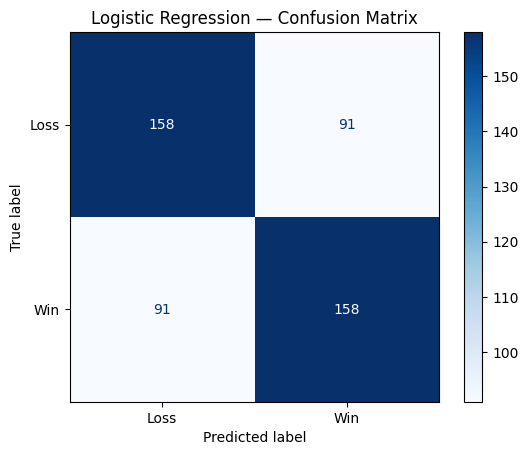


Random Forest
              precision    recall  f1-score   support

        Loss       0.58      0.59      0.59       249
         Win       0.58      0.57      0.57       249

    accuracy                           0.58       498
   macro avg       0.58      0.58      0.58       498
weighted avg       0.58      0.58      0.58       498



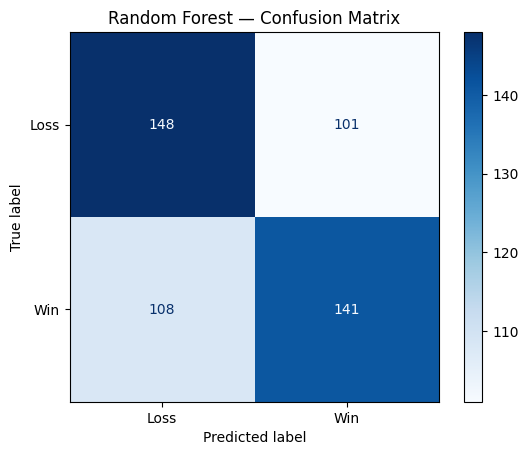


XGBoost
              precision    recall  f1-score   support

        Loss       0.62      0.63      0.63       249
         Win       0.62      0.62      0.62       249

    accuracy                           0.62       498
   macro avg       0.62      0.62      0.62       498
weighted avg       0.62      0.62      0.62       498



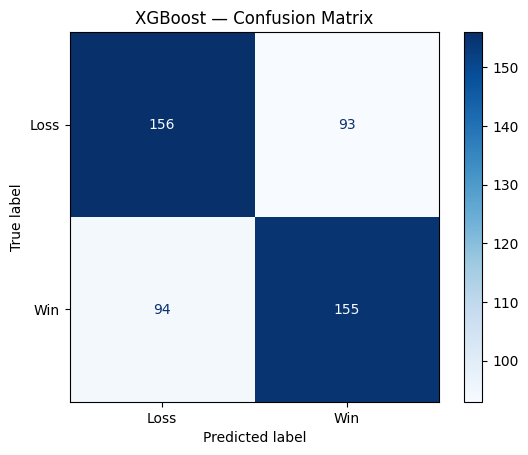

In [7]:
baseline_accuracy = accuracy_score(y_test_binary, np.ones(len(y_test_binary), dtype=int))
print(f"Always-win baseline accuracy: {baseline_accuracy:.4f}")
for name, model in models.items():
    predictions = model.predict(X_test)
    print(f"\n{name}\n{classification_report(y_test_binary, predictions, target_names=['Loss', 'Win'])}")
    ConfusionMatrixDisplay.from_predictions(y_test_binary, predictions, display_labels=["Loss", "Win"], cmap="Blues")
    plt.title(f"{name} — Confusion Matrix")
    plt.show()

## 8. Game-level validation

For each game, count predicted winning teams. Exactly one winner is logically consistent; zero or two indicates contradictory predictions. Also report winner-selection accuracy for each model by choosing the team with the higher predicted win probability.

In [8]:
game_validation = []
for name, model in models.items():
    rows = test_df_improved[["GAME_ID", "TEAM_ABBREVIATION_x", "WL_x"]].copy()
    rows["PREDICTED_WIN"] = model.predict(X_test)
    rows["WIN_PROBABILITY"] = model.predict_proba(X_test)[:, 1]
    win_counts = rows.groupby("GAME_ID")["PREDICTED_WIN"].sum()
    selected = rows.loc[rows.groupby("GAME_ID")["WIN_PROBABILITY"].idxmax()]
    game_validation.append({
        "Model": name,
        "Test Games": len(win_counts),
        "Exactly One Winner": int((win_counts == 1).sum()),
        "Contradictory Games": int((win_counts != 1).sum()),
        "Winner Selection Accuracy": (selected["WL_x"] == "W").mean(),
    })
game_validation_df = pd.DataFrame(game_validation)
game_validation_df.round(4)

,Model,Test Games,Exactly One Winner,Contradictory Games,Winner Selection Accuracy
0,Logistic Regression,249,249,0,0.6345
1,Random Forest,249,216,33,0.5823
2,XGBoost,249,242,7,0.6265


## 9. Conclusion and limitations

Logistic Regression is the strongest model in the current test comparison. Results should be interpreted as **historical holdout performance**, not guaranteed future accuracy. This project uses a single NBA season and a limited set of historical statistics. Future work: test on an independent season, investigate probability calibration, and compare against stronger basketball-specific baselines. No hyperparameter tuning was performed on the test set.